In [41]:
#imported libraries
import numpy as np
import librosa
import soundfile as sf

In [42]:
# Load the audio file
input_path = 'OutputData/blues/blues.00000.wav'
audio_data, sr = librosa.load(input_path, sr=None)

# Parameters for adaptive temporal masking
frame_size = 2048
hop_length = 256
masking_factor = 0.005

# Compute Short-Time Fourier Transform (STFT)
stft = librosa.stft(audio_data, n_fft=frame_size, hop_length=hop_length)
magnitude, phase = np.abs(stft), np.angle(stft)

# Calculate frame energies (sum of squared magnitudes per frame)
frame_energies = np.sum(magnitude ** 2, axis=0)

# Initialize thresholds array with the same length as the number of time frames
thresholds = np.zeros_like(frame_energies)

# Adaptive masking: compute threshold for each time frame
for i in range(1, len(frame_energies)):
    thresholds[i] = max(
        frame_energies[i] * masking_factor,  # Current frame
        thresholds[i - 1] * 0.8  # Decay previous threshold
    )

# Reshape thresholds to match the shape of the magnitude array for broadcasting
thresholds = thresholds[np.newaxis, :]  # Add a new axis to align with magnitude shape

# Apply masking: zero out magnitudes below thresholds
masked_magnitude = np.where(
    magnitude > thresholds,
    magnitude,
    0
)

# Reconstruct the masked STFT
masked_stft = masked_magnitude * np.exp(1j * phase)

# Inverse STFT to convert back to time domain
masked_audio = librosa.istft(masked_stft, hop_length=hop_length)

# Save the masked audio
output_path = 'OutputData/adaptive_tm/masked_file.wav'
sf.write(output_path, masked_audio, sr)

print(f"Masked audio saved at: {output_path}")


Masked audio saved at: OutputData/adaptive_tm/masked_file.wav


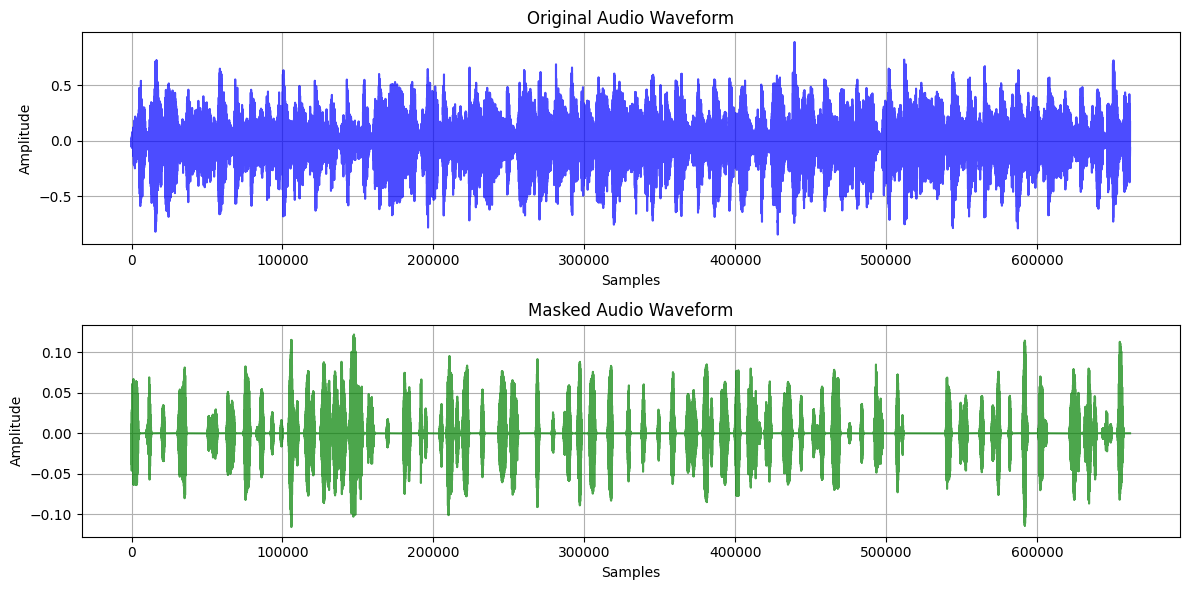

In [43]:
# Plotting the input and output waveforms
plt.figure(figsize=(12, 6))

# Plot the original audio
plt.subplot(2, 1, 1)
plt.plot(audio_data, color='blue', alpha=0.7)
plt.title("Original Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)

# Plot the masked audio
plt.subplot(2, 1, 2)
plt.plot(masked_audio, color='green', alpha=0.7)
plt.title("Masked Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)

# Display the plots
plt.tight_layout()
plt.show()